In [23]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import time

In [24]:
class Linear():
  ''' y = X @ W + b '''
  def __init__(self, in_feat, out_feat):
    scale = np.sqrt(2.0 / in_feat)
    self.W = np.random.randn(in_feat, out_feat) * scale
    self.b = np.zeros((1, out_feat))
    self.dW = None
    self.db = None
    self.X = None
    self.dX = None

  def forward(self, X):
    self.X = X # B x input
    return X @ self.W + self.b # B x output

  def backward(self, grad):
    self.dW = self.X.T @ grad # dy/dw
    self.db = grad.sum(axis=0, keepdims=True) # dy/db
    self.dX = grad @ self.W.T # dy/dx
    return self.dX

  def params_and_grads(self):
    return [(self.W, self.dW), (self.b, self.db)]

  def __repr__(self):
    return f"Linear({self.W.shape[0]}, {self.W.shape[1]})"

In [25]:
class ReLU():
  ''' y = max(0, x) '''
  def __init__(self):
    self.mask = None

  def forward(self, X):
    self.mask = (X > 0)
    return X * self.mask

  def backward(self, grad):
    return grad * self.mask

  def params_and_grads(self):
      return []

  def __repr__(self):
      return "ReLU()"

In [26]:
class SoftMaxCrossEntropy:
    """Softmax + CrossEntropy"""

    def __init__(self):
        self.prob = None
        self.y    = None

    def forward(self, z, y):
        """
        z: (B, C) — логиты
        y: (B, C) — one-hot метки
        return: скаляр loss
        """
        # Softmax (устойчивый)
        z_shift = z - z.max(axis=1, keepdims=True)
        exp_z   = np.exp(z_shift)
        prob    = exp_z / exp_z.sum(axis=1, keepdims=True)   # (B, C)

        # 2. CrossEntropy
        eps = 1e-12
        loss = -np.mean(np.sum(y * np.log(prob + eps), axis=1))

        self.prob = prob
        self.y    = y

        return loss

    def backward(self):
        """ z: dL/dz """
        B = self.y.shape[0]
        return (self.prob - self.y) / B

    def params_and_grads(self):
        return []

    def __repr__(self):
        return "SoftMaxCrossEntropy()"

In [28]:
class NN():
  def __init__(self, layers, loss):
    self.layers = layers
    self.loss = loss

  def forward(self, X):
    h = X
    for layer in self.layers:
      h = layer.forward(h)
    return h

  def compute_loss(self, X, y):
    logits = self.forward(X)
    return self.loss.forward(logits, y)

  def backward(self):
    grad = self.loss.backward()
    for layer in reversed(self.layers):
        grad = layer.backward(grad)

  def params_and_grads(self):
        out = []
        for layer in self.layers:
            out.extend(layer.params_and_grads())
        return out

  def fit(self, X, y, epochs, batch_size, optimizer, verbose=True):
        n = len(X)
        for epoch in range(epochs):
            t_start = time.time()

            # --- shuffle ---
            idx = np.random.permutation(n)
            X_sh, y_sh = X[idx], y[idx]

            # --- батчи ---
            for i in range(0, n, batch_size):
                xb = X_sh[i:i+batch_size]
                yb = y_sh[i:i+batch_size]
                self.compute_loss(xb, yb)          # forward + loss
                self.backward()                     # backward
                optimizer.step(self.params_and_grads())  # step

            t_end = time.time()
            if verbose:
                train_err = self.error(X, y)
                print(f"epoch {epoch+1:3d} | "
                      f"train error = {train_err:.4f} | "
                      f"time = {t_end - t_start:.2f}s")

  def error(self, X, y):
        y_pred = self.predict(X)
        y_true = np.argmax(y, axis=1)
        return (y_pred != y_true).mean()

  def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

In [29]:
class SGD():
  def __init__(self, lr):
    self.lr = lr

  def step(self, params_and_grads):
    for param, grad in params_and_grads:
      param -= self.lr * grad

In [30]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X = mnist.data.astype(np.float32) / 255.0     # (70000, 784), значения [0, 1]
y = mnist.target.astype(np.int64)              # (70000,) индексы 0..9

n = len(X)
n_train = 60000

def one_hot(y, num_classes=10):
    return np.eye(num_classes)[y].astype(np.float32)

Y = one_hot(y)      # (70000, 10)
X_train, Y_train = X[:n_train], Y[:n_train]
X_test,  Y_test  = X[n_train:], Y[n_train:]

In [31]:
net = NN(layers = [Linear(784, 128), ReLU(), Linear(128, 10)], loss = SoftMaxCrossEntropy())
net.fit(X_train, Y_train, epochs = 5, batch_size = 64, optimizer = SGD(lr = 0.1))
y_pred = net.predict(X_test)
y_pred

epoch   1 | train error = 0.0658 | time = 6.43s
epoch   2 | train error = 0.0482 | time = 2.85s
epoch   3 | train error = 0.0351 | time = 2.89s
epoch   4 | train error = 0.0325 | time = 6.15s
epoch   5 | train error = 0.0240 | time = 2.89s


array([7, 2, 1, ..., 4, 5, 6])

X_train: (60000, 784)
Y_train: (60000, 10)
X_test:  (10000, 784)
Y_test:  (10000, 10)

Количество примеров:
  train: 60000
  test:  10000

Форма одного изображения:
  flattened: (784,)
  как 2D:    (28, 28)


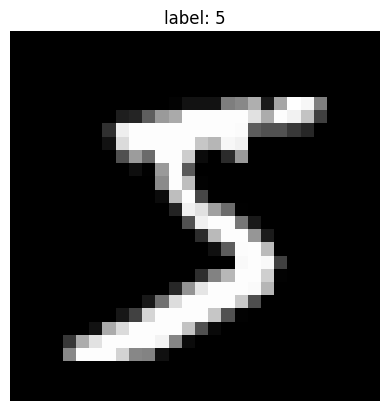


Форма одной метки:
  one-hot: (10,)
  класс:   5

Типы данных:
  X.dtype: float32
  Y.dtype: float32

Диапазон значений X:
  min: 0.0  max: 1.0


In [32]:
import numpy as np
import matplotlib.pyplot as plt

print("X_train:", X_train.shape)          # (60000, 784)
print("Y_train:", Y_train.shape)          # (60000, 10)
print("X_test: ", X_test.shape)           # (10000, 784)
print("Y_test: ", Y_test.shape)           # (10000, 10)

print("\nКоличество примеров:")
print("  train:", X_train.shape[0])
print("  test: ", X_test.shape[0])

print("\nФорма одного изображения:")
print("  flattened:", X_train.shape[1:])
print("  как 2D:   ", (28, 28))

i = 0
img = X_train[i].reshape(28, 28)
label = np.argmax(Y_train[i])

plt.imshow(img, cmap='gray')
plt.title(f"label: {label}")
plt.axis('off')
plt.show()

print("\nФорма одной метки:")
print("  one-hot:", Y_train.shape[1:])    # (10,)
print("  класс:  ", np.argmax(Y_train[0])) # индекс

print("\nТипы данных:")
print("  X.dtype:", X_train.dtype)        # float32/float64
print("  Y.dtype:", Y_train.dtype)        # float32/float64

print("\nДиапазон значений X:")
print("  min:", X_train.min(), " max:", X_train.max())   # 0.0 .. 1.0

In [33]:
net = NN(
    layers=[
        Linear(784, 300),
        ReLU(),
        Linear(300, 10),
    ],
    loss=SoftMaxCrossEntropy(),
)

net.fit(
    X_train, Y_train,
    epochs=20,
    batch_size=64,
    optimizer=SGD(lr=0.1),
    verbose=True,
)

test_err = net.error(X_test, Y_test)
print(f"\nTest error: {test_err:.4f}  (accuracy = {1-test_err:.4f})")

epoch   1 | train error = 0.0662 | time = 9.11s
epoch   2 | train error = 0.0416 | time = 6.14s
epoch   3 | train error = 0.0335 | time = 7.37s
epoch   4 | train error = 0.0258 | time = 9.08s
epoch   5 | train error = 0.0236 | time = 5.92s
epoch   6 | train error = 0.0197 | time = 8.07s
epoch   7 | train error = 0.0162 | time = 9.05s
epoch   8 | train error = 0.0141 | time = 6.03s
epoch   9 | train error = 0.0120 | time = 8.79s
epoch  10 | train error = 0.0099 | time = 9.24s
epoch  11 | train error = 0.0094 | time = 6.05s
epoch  12 | train error = 0.0080 | time = 8.86s
epoch  13 | train error = 0.0076 | time = 9.00s
epoch  14 | train error = 0.0060 | time = 6.04s
epoch  15 | train error = 0.0048 | time = 8.98s
epoch  16 | train error = 0.0042 | time = 9.06s
epoch  17 | train error = 0.0037 | time = 6.01s
epoch  18 | train error = 0.0030 | time = 9.09s
epoch  19 | train error = 0.0028 | time = 9.15s
epoch  20 | train error = 0.0033 | time = 6.14s

Test error: 0.0212  (accuracy = 0.9788)